## 0 — Montar Google Drive e instalar dependências

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
%cd /content/drive/MyDrive/proj\ 2\ MS671
!pip install Faker babel --quiet
print('Pronto.')


/content/drive/MyDrive/proj 2 MS671
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 33.4 MB/s eta 0:00:00
Pronto.


## 1 — Imports

In [ ]:
import os, warnings, pickle
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
warnings.filterwarnings('ignore')

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import tensorflow as tf
from tensorflow.keras.layers import (
    Bidirectional, Concatenate, Dot, Input, LSTM,
    RepeatVector, Dense, Activation
)
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
import tensorflow.keras.backend as K

print(f'TensorFlow {tf.__version__}')
print('GPU:', tf.config.list_physical_devices("GPU"))


TensorFlow 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2 — Carregar dataset e vocabulários do Drive

In [ ]:
with open('dataset.pkl',          'rb') as f: dataset          = pickle.load(f)
with open('human_vocab.pkl',      'rb') as f: human_vocab      = pickle.load(f)
with open('machine_vocab.pkl',    'rb') as f: machine_vocab    = pickle.load(f)
with open('inv_machine_vocab.pkl','rb') as f: inv_machine_vocab = pickle.load(f)

print(f'Dataset: {len(dataset):,} exemplos')
print(f'|human_vocab|   = {len(human_vocab)}')
print(f'|machine_vocab| = {len(machine_vocab)}')
print(f'inv_machine_vocab: {inv_machine_vocab}')
print()
print('Primeiros 5 exemplos:')
for h, t in dataset[:5]:
    print(f'  "{h}"  ->  "{t}"')


Dataset: 10,000 exemplos
|human_vocab|   = 37
|machine_vocab| = 11
inv_machine_vocab: {0: '-', 1: '0', 2: '1', 3: '2', 4: '3', 5: '4', 6: '5', 7: '6', 8: '7', 9: '8', 10: '9'}

Primeiros 5 exemplos:
  "9 may 1998"  ->  "1998-05-09"
  "10.11.19"  ->  "2019-11-10"
  "9/10/70"  ->  "1970-09-10"
  "saturday april 28 1990"  ->  "1990-04-28"
  "thursday january 26 1995"  ->  "1995-01-26"


## 3 — Pré-processamento dos dados

In [ ]:
Tx = 30   # comprimento máximo da entrada
Ty = 10   # comprimento fixo da saída (YYYY-MM-DD)
m  = len(dataset)

def string_to_int(string, length, vocab):
    """Converte uma string em lista de índices do vocabulário."""
    string = string.lower().replace(',', '')
    if len(string) > length:
        string = string[:length]
    rep = list(map(lambda x: vocab.get(x, vocab.get('<unk>', 35)), string))
    if len(string) < length:
        rep += [vocab['<pad>']] * (length - len(string))
    return rep

def int_to_string(ints, inv_vocab):
    """Converte lista de índices de volta para string."""
    return [inv_vocab[i] for i in ints]

def preprocess_data(dataset, human_vocab, machine_vocab, Tx, Ty):
    X_raw, Y_raw = zip(*dataset)
    X   = np.array([string_to_int(s, Tx, human_vocab)   for s in X_raw])
    Y   = np.array([string_to_int(s, Ty, machine_vocab) for s in Y_raw])
    Xoh = np.array([to_categorical(x, num_classes=len(human_vocab))   for x in X])
    Yoh = np.array([to_categorical(y, num_classes=len(machine_vocab)) for y in Y])
    return X, Y, Xoh, Yoh

X, Y, Xoh, Yoh = preprocess_data(dataset, human_vocab, machine_vocab, Tx, Ty)

print('X.shape  :', X.shape,   '  → (m, Tx)')
print('Y.shape  :', Y.shape,   '  → (m, Ty)')
print('Xoh.shape:', Xoh.shape, '  → (m, Tx, |Vx|)')
print('Yoh.shape:', Yoh.shape, '  → (m, Ty, |Vy|)')


X.shape  : (10000, 30)   → (m, Tx)
Y.shape  : (10000, 10)   → (m, Ty)
Xoh.shape: (10000, 30, 37)   → (m, Tx, |Vx|)
Yoh.shape: (10000, 10, 11)   → (m, Ty, |Vy|)


## 4 — Definição do modelo




In [ ]:
def softmax(x, axis=1):
    """Softmax ao longo do eixo 1 (comprimento da sequência de entrada)."""
    e = K.exp(x - K.max(x, axis=axis, keepdims=True))
    return e / K.sum(e, axis=axis, keepdims=True)

# ── Camadas compartilhadas (mesmos nomes do modelo salvo) ─────────────────────
n_a = 32   # unidades da Bi-LSTM  (pré-atenção)
n_s = 64   # unidades da LSTM     (pós-atenção / decoder)

repeator      = RepeatVector(Tx)
concatenator  = Concatenate(axis=-1)
densor1       = Dense(10, activation='tanh', name='dense_36')   # energia intermediária
densor2       = Dense(1,  activation='relu', name='dense_37')   # energia escalar
activator     = Activation(softmax,          name='attention_weights')
dotor         = Dot(axes=1)

post_activation_LSTM_cell = LSTM(n_s, return_state=True, name='lstm_20')
output_layer  = Dense(len(machine_vocab), activation=softmax, name='dense_38')

print('Camadas compartilhadas definidas.')
print(f'  n_a (Bi-LSTM) = {n_a}  |  n_s (Decoder LSTM) = {n_s}')


Camadas compartilhadas definidas.
  n_a (Bi-LSTM) = 32  |  n_s (Decoder LSTM) = 64


### 4.2 — Passo de atenção (`one_step_attention`)




In [ ]:
def one_step_attention(a, s_prev):
    """
    Calcula o vetor de contexto em um passo do decoder.

    a      : saídas da Bi-LSTM, shape (m, Tx, 2*n_a)
    s_prev : estado oculto anterior do decoder, shape (m, n_s)
    retorna: context, shape (m, 1, 2*n_a)
    """
    s_prev   = repeator(s_prev)           # (m, Tx, n_s)   — repete s_prev Tx vezes
    concat   = concatenator([a, s_prev])  # (m, Tx, 2*n_a + n_s)
    e        = densor1(concat)            # (m, Tx, 10)    — energia intermediária (tanh)
    energies = densor2(e)                # (m, Tx, 1)     — energia escalar (relu)
    alphas   = activator(energies)        # (m, Tx, 1)     — pesos de atenção (softmax)
    context  = dotor([alphas, a])         # (m, 1, 2*n_a)  — vetor de contexto
    return context

print('one_step_attention definida.')


one_step_attention definida.


### 4.3 — Modelo completo

In [ ]:
def modelf(Tx, Ty, n_a, n_s, human_vocab_size, machine_vocab_size):
    """
    Constrói o modelo NMT com atenção de Bahdanau.

    Entradas : [X(m,Tx,|Vx|), s0(m,n_s), c0(m,n_s)]
    Saídas   : lista de Ty arrays (m, |Vy|)
    """
    X_in = Input(shape=(Tx, human_vocab_size), name='input_10')
    s0   = Input(shape=(n_s,), name='s0')
    c0   = Input(shape=(n_s,), name='c0')
    s, c = s0, c0
    outputs = []

    # Encoder: Bi-LSTM lê toda a entrada
    a = Bidirectional(LSTM(n_a, return_sequences=True), name='bidirectional_10')(X_in)

    # Decoder: Ty passos autorregressivos
    for t in range(Ty):
        context    = one_step_attention(a, s)
        s, _, c    = post_activation_LSTM_cell(context, initial_state=[s, c])
        out        = output_layer(s)
        outputs.append(out)

    return Model(inputs=[X_in, s0, c0], outputs=outputs)

model = modelf(Tx, Ty, n_a, n_s, len(human_vocab), len(machine_vocab))
model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_10            │ (None, 30, 37)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ s0 (InputLayer)     │ (None, 64)        │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_10    │ (None, 30, 64)    │     17,920 │ input_10[0][0]    │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_vector       │ (None, 30, 64)    │          0 │ s0[0][0],         │
│ (RepeatVector)      │                   │            │ lstm_20[0][0],    │
│                     │                   │            │ lstm_20[1][0],    │
│                     │                   │            │ lstm_20[2][0],    │
│                     │                   │            │ lstm_20[3][0],    │
│                     │                   │            │ lstm_20[4][0],    │
│                     │                   │            │ lstm_20[5][0],    │
│                     │                   │            │ lstm_20[6][0],    │
│                     │                   │            │ lstm_20[7][0],    │
│                     │                   │            │ lstm_20[8][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 30, 128)   │          0 │ bidirectional_10… │
│ (Concatenate)       │                   │            │ repeat_vector[0]… │
│                     │                   │            │ bidirectional_10… │
│                     │                   │            │ repeat_vector[1]… │
│                     │                   │            │ bidirectional_10… │
│                     │                   │            │ repeat_vector[2]… │
│                     │                   │            │ bidirectional_10… │
│                     │                   │            │ repeat_vector[3]… │
│                     │                   │            │ bidirectional_10… │
│                     │                   │            │ repeat_vector[4]… │
│                     │                   │            │ bidirectional_10… │
│                     │                   │            │ repeat_vector[5]… │
│                     │                   │            │ bidirectional_10… │
│                     │                   │            │ repeat_vector[6]… │
│                     │                   │            │ bidirectional_10… │
│                     │                   │            │ repeat_vector[7]… │
│                     │                   │            │ bidirectional_10… │
│                     │                   │            │ repeat_vector[8]… │
│                     │                   │            │ bidirectional_10… │
│                     │                   │            │ repeat_vector[9]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_36 (Dense)    │ (None, 30, 10)    │      1,290 │ concatenate[0][0… │
│                     │                   │            │ concatenate[1][0… │
│                     │                   │            │ concatenate[2][0… │
│                     │                   │            │ concatenate[3][0… │
│                     │                   │            │ concatenate[4][0… │
│                     │                   │            │ concatenate[5][0… │
│                     │                   │            │ concatenate[6][0… │
│                     │                   │            │ concatenate[7][0… │
│                     │                   │            │ concatenate[8][0

 Total params: 52,960 (206.88 KB)

 Trainable params: 52,960 (206.88 KB)

 Non-trainable params: 0 (0.00 B)

## 5 — Compilação do modelo

In [ ]:
opt = Adam(learning_rate=0.005, beta_1=0.9, beta_2=0.999, weight_decay=0.01)
model.compile(
    optimizer=opt,
    loss='categorical_crossentropy',
    metrics=['accuracy'] * Ty
)

s0_train = np.zeros((m, n_s))
c0_train = np.zeros((m, n_s))
outputs_train = list(Yoh.swapaxes(0, 1))  # lista de Ty arrays (m, |Vy|)

print('Modelo compilado.')
print('Shapes dos targets:', [o.shape for o in outputs_train[:2]], '...')


Modelo compilado.
Shapes dos targets: [(10000, 11), (10000, 11)] ...


## 6 — Treinamento e comparação de desempenho

### 6.1 — Treinamento do zero: 1 época (baseline)


In [ ]:
print('=' * 55)
print('Treinando do zero por 1 época...')
print('=' * 55)

history_1ep = model.fit(
    [Xoh, s0_train, c0_train],
    outputs_train,
    epochs=1,
    batch_size=100,
    verbose=1
)
print(f'\nLoss após 1 época: {history_1ep.history["loss"][-1]:.4f}')


Treinando do zero por 1 época...
100/100 ━━━━━━━━━━━━━━━━━━━━ 20s 34ms/step - dense_38_accuracy: 0.5503 - dense_38_accuracy_1: 0.7082 - dense_38_accuracy_2: 0.3003 - dense_38_accuracy_3: 0.0988 - dense_38_accuracy_4: 0.9741 - dense_38_accuracy_5: 0.4197 - dense_38_accuracy_6: 0.0877 - dense_38_accuracy_7: 0.9407 - dense_38_accuracy_8: 0.2533 - dense_38_accuracy_9: 0.0991 - dense_38_loss: 2.5357 - loss: 15.6033

Loss após 1 época: 15.6033


In [ ]:
# ── Função de predição ────────────────────────────────────────────────────────
s00 = np.zeros((1, n_s))
c00 = np.zeros((1, n_s))

def predict_date(sentence, model=model):
    src = string_to_int(sentence, Tx, human_vocab)
    src = np.array([to_categorical(x, num_classes=len(human_vocab)) for x in src])
    src = np.expand_dims(src, axis=0)            # (1, Tx, |Vx|)
    preds = model.predict([src, s00, c00], verbose=0)
    chars = [inv_machine_vocab[int(np.argmax(p))] for p in preds]
    return ''.join(chars)

EXAMPLES = [
    '3 May 1979', '5 April 09', '21th of August 2016',
    'Tue 10 Jul 2007', 'Saturday May 9 2018',
    'March 3 2001', 'March 3rd 2001', '1 March 2001'
]

print('Resultados após 1 época:')
print(f'{"Entrada":<30} {"Predição":<12}')
print('-' * 45)
for ex in EXAMPLES:
    print(f'{ex:<30} {predict_date(ex)}')


Resultados após 1 época:
Entrada                        Predição    
---------------------------------------------
3 May 1979                     1997-07-04
5 April 09                     1987-07-07
21th of August 2016            2000-00-08
Tue 10 Jul 2007                2000-07-07
Saturday May 9 2018            1983-07-07
March 3 2001                   2000-03-03
March 3rd 2001                 2000-03-03
1 March 2001                   2000-02-22


### 6.2 — Treinamento do zero: 50 épocas

In [ ]:
print('=' * 55)
print('Continuando treinamento (+ 49 épocas = 50 total)...')
print('=' * 55)

history_50ep = model.fit(
    [Xoh, s0_train, c0_train],
    outputs_train,
    epochs=49,
    batch_size=100,
    verbose=1
)
print(f'\nLoss final (50 épocas): {history_50ep.history["loss"][-1]:.4f}')


Continuando treinamento (+ 49 épocas = 50 total)...
Epoch 1/49
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - dense_38_accuracy: 0.9971 - dense_38_accuracy_1: 0.9943 - dense_38_accuracy_2: 0.9500 - dense_38_accuracy_3: 0.8444 - dense_38_accuracy_4: 0.9957 - dense_38_accuracy_5: 0.9365 - dense_38_accuracy_6: 0.7482 - dense_38_accuracy_7: 0.8926 - dense_38_accuracy_8: 0.7913 - dense_38_accuracy_9: 0.8012 - dense_38_loss: 0.5968 - loss: 3.3234
Epoch 2/49
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - dense_38_accuracy: 1.0000 - dense_38_accuracy_1: 1.0000 - dense_38_accuracy_2: 0.9997 - dense_38_accuracy_3: 0.9965 - dense_38_accuracy_4: 1.0000 - dense_38_accuracy_5: 0.9910 - dense_38_accuracy_6: 0.9939 - dense_38_accuracy_7: 1.0000 - dense_38_accuracy_8: 0.9965 - dense_38_accuracy_9: 0.9990 - dense_38_loss: 0.0096 - loss: 0.1429
Epoch 3/49
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - dense_38_accuracy: 1.0000 - dense_38_accuracy_1: 1.0000 - dense_38_accuracy_2: 0.9997 - dense_38_accuracy_3: 0.99

In [ ]:
print('Resultados após 50 épocas:')
print(f'{"Entrada":<30} {"Predição":<12}')
print('-' * 45)
for ex in EXAMPLES:
    print(f'{ex:<30} {predict_date(ex)}')


Resultados após 50 épocas:
Entrada                        Predição    
---------------------------------------------
3 May 1979                     1979-05-33
5 April 09                     2009-04-05
21th of August 2016            2016-08-20
Tue 10 Jul 2007                2007-07-10
Saturday May 9 2018            2018-05-09
March 3 2001                   2001-03-03
March 3rd 2001                 2001-03-03
1 March 2001                   2001-03-01


### 6.3 — Modelo pré-treinado (carregando `model.h5`)

In [ ]:
# Recarrega os pesos pré-treinados por cima do modelo já construído
model.load_weights('model.h5')
print('Pesos pré-treinados carregados de model.h5')
print()
print('Resultados com modelo pré-treinado:')
print(f'{"Entrada":<30} {"Predição":<12}')
print('-' * 45)
for ex in EXAMPLES:
    print(f'{ex:<30} {predict_date(ex)}')


Pesos pré-treinados carregados de model.h5

Resultados com modelo pré-treinado:
Entrada                        Predição    
---------------------------------------------
3 May 1979                     1979-05-33
5 April 09                     2009-04-05
21th of August 2016            2016-08-20
Tue 10 Jul 2007                2007-07-10
Saturday May 9 2018            2018-05-09
March 3 2001                   2001-03-03
March 3rd 2001                 2001-03-03
1 March 2001                   2001-03-01


### 6.4 — Curva de aprendizado (50 épocas treinadas do zero)

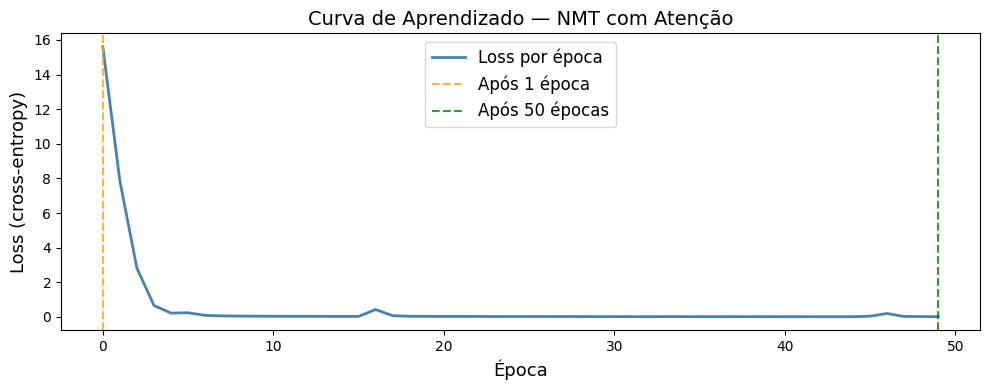

In [ ]:
all_losses = history_1ep.history['loss'] + history_50ep.history['loss']

plt.figure(figsize=(10, 4))
plt.plot(all_losses, color='steelblue', linewidth=2, label='Loss por época')
plt.axvline(x=0,  color='orange', linestyle='--', alpha=0.8, label='Após 1 época')
plt.axvline(x=49, color='green',  linestyle='--', alpha=0.8, label='Após 50 épocas')
plt.xlabel('Época', fontsize=13)
plt.ylabel('Loss (cross-entropy)', fontsize=13)
plt.title('Curva de Aprendizado — NMT com Atenção', fontsize=14)
plt.legend(fontsize=12)
plt.tight_layout()
plt.savefig('learning_curve.png', dpi=150)
plt.show()


## 7 — Experimento: variação de `n_a` (Bi-LSTM) e `n_s` (Decoder LSTM)



In [ ]:
CONFIGS = [
    {'n_a': 16, 'n_s': 32,  'label': 'Pequeno  (n_a=16, n_s=32)'},
    {'n_a': 32, 'n_s': 64,  'label': 'Médio    (n_a=32, n_s=64) — padrão'},
    {'n_a': 64, 'n_s': 128, 'label': 'Grande   (n_a=64, n_s=128)'},
]
EPOCHS_EXP = 20
config_results = {}

for cfg in CONFIGS:
    _na, _ns = cfg['n_a'], cfg['n_s']
    print(f"\n{'='*55}")
    print(f"Config: {cfg['label']}")

    # Redefine camadas com este tamanho
    _rep  = RepeatVector(Tx)
    _cat  = Concatenate(axis=-1)
    _d1   = Dense(10, activation='tanh')
    _d2   = Dense(1,  activation='relu')
    _act  = Activation(softmax)
    _dot  = Dot(axes=1)
    _lstm = LSTM(_ns, return_state=True)
    _out  = Dense(len(machine_vocab), activation=softmax)

    def _attn(a, s_prev):
        sp = _rep(s_prev); cc = _cat([a, sp])
        e  = _d1(cc); en = _d2(e); al = _act(en)
        return _dot([al, a])

    Xi = Input(shape=(Tx, len(human_vocab)))
    _s0 = Input(shape=(_ns,), name='s0')
    _c0 = Input(shape=(_ns,), name='c0')
    _s, _c = _s0, _c0
    _outs = []
    _a = Bidirectional(LSTM(_na, return_sequences=True))(Xi)
    for t in range(Ty):
        _ctx = _attn(_a, _s)
        _s, _, _c = _lstm(_ctx, initial_state=[_s, _c])
        _outs.append(_out(_s))

    m_exp = Model(inputs=[Xi, _s0, _c0], outputs=_outs)
    m_exp.compile(optimizer=Adam(learning_rate=0.005),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'] * Ty)

    _s0t = np.zeros((m, _ns)); _c0t = np.zeros((m, _ns))
    hist = m_exp.fit([Xoh, _s0t, _c0t], outputs_train,
                     epochs=EPOCHS_EXP, batch_size=100, verbose=0)

    _s00 = np.zeros((1, _ns)); _c00 = np.zeros((1, _ns))
    preds_exp = []
    for ex in EXAMPLES:
        src = string_to_int(ex, Tx, human_vocab)
        src = np.array([to_categorical(x, num_classes=len(human_vocab)) for x in src])
        src = np.expand_dims(src, 0)
        p = m_exp.predict([src, _s00, _c00], verbose=0)
        preds_exp.append(''.join(inv_machine_vocab[int(np.argmax(pp))] for pp in p))

    config_results[cfg['label']] = {
        'loss_curve': hist.history['loss'],
        'final_loss': hist.history['loss'][-1],
        'predictions': preds_exp,
    }
    print(f"Loss final ({EPOCHS_EXP} ép): {hist.history['loss'][-1]:.4f}")
    for ex, p in zip(EXAMPLES, preds_exp):
        print(f'  {ex:<28} -> {p}')



Config: Pequeno  (n_a=16, n_s=32)
Loss final (20 ép): 0.0322
  3 May 1979                   -> 1979-05-03
  5 April 09                   -> 2009-04-05
  21th of August 2016          -> 2016-08-21
  Tue 10 Jul 2007              -> 2007-07-10
  Saturday May 9 2018          -> 2018-05-09
  March 3 2001                 -> 2001-03-03
  March 3rd 2001               -> 2001-03-03
  1 March 2001                 -> 2001-03-01

Config: Médio    (n_a=32, n_s=64) — padrão
Loss final (20 ép): 0.0360
  3 May 1979                   -> 1979-05-03
  5 April 09                   -> 2009-04-05
  21th of August 2016          -> 2016-02-21
  Tue 10 Jul 2007              -> 2007-07-10
  Saturday May 9 2018          -> 2018-05-09
  March 3 2001                 -> 2001-03-03
  March 3rd 2001               -> 2001-01-03
  1 March 2001                 -> 2001-03-01

Config: Grande   (n_a=64, n_s=128)
Loss final (20 ép): 0.0128
  3 May 1979                   -> 1979-05-03
  5 April 09                   -> 2009-

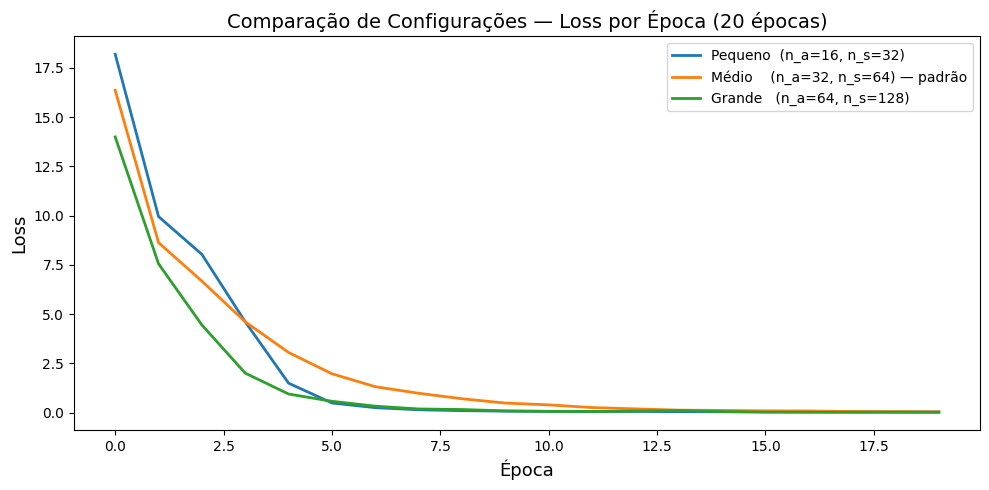


Resumo:
Configuração                          Loss final
--------------------------------------------------
Pequeno  (n_a=16, n_s=32)                 0.0322
Médio    (n_a=32, n_s=64) — padrão        0.0360
Grande   (n_a=64, n_s=128)                0.0128


In [ ]:
# Comparação gráfica
plt.figure(figsize=(10, 5))
for label, res in config_results.items():
    plt.plot(res['loss_curve'], label=label, linewidth=2)
plt.xlabel('Época', fontsize=13)
plt.ylabel('Loss', fontsize=13)
plt.title('Comparação de Configurações — Loss por Época (20 épocas)', fontsize=14)
plt.legend(fontsize=10)
plt.tight_layout()
plt.savefig('config_comparison.png', dpi=150)
plt.show()

print('\nResumo:')
print(f'{"Configuração":<35} {"Loss final":>12}')
print('-' * 50)
for label, res in config_results.items():
    print(f'{label:<35} {res["final_loss"]:>12.4f}')


## 8 — Mapa de Atenção



In [ ]:
def plot_attention_map(modelx, input_vocabulary, inv_output_vocabulary,
                       text, n_s=64, Tx=30, Ty=10, save_as=None):
    """
    Extrai e plota os pesos de atenção alpha^{t,t'} para uma frase de entrada.
    Reconstrói parcialmente o grafo seguindo os índices do modelo original.
    """
    attention_map = np.zeros((Ty, Tx))

    # ── Reconstrói o sub-grafo de atenção usando as camadas do modelo ─────────
    X_inp = modelx.inputs[0]   # (1, Tx, |Vx|)
    s0_   = modelx.inputs[1]   # (1, n_s)
    c0_   = modelx.inputs[2]   # (1, n_s)
    s     = s0_
    c     = s0_   # inicial identico ao original

    a = modelx.layers[2](X_inp)   # Bi-LSTM

    energy_outputs = []
    for t in range(Ty):
        s_prev   = modelx.layers[3](s)          # RepeatVector
        concat   = modelx.layers[4]([a, s_prev]) # Concatenate
        e        = modelx.layers[5](concat)      # Dense (tanh)
        energies = modelx.layers[6](e)           # Dense (relu)
        alphas   = modelx.layers[7](energies)    # Activation (softmax)
        context  = modelx.layers[8]([alphas, a]) # Dot
        s, _, c  = modelx.layers[10](context, initial_state=[s, c])  # LSTM decoder
        energy_outputs.append(energies)

    f_attn = Model(inputs=[X_inp, s0_, c0_], outputs=energy_outputs)

    # ── Pré-processa a entrada ─────────────────────────────────────────────────
    s0_pred = np.zeros((1, n_s))
    c0_pred = np.zeros((1, n_s))
    src     = string_to_int(text, Tx, input_vocabulary)
    src_oh  = np.array([to_categorical(x, num_classes=len(input_vocabulary)) for x in src])
    src_oh  = np.expand_dims(src_oh, 0)   # (1, Tx, |Vx|)

    # ── Extrai energias ────────────────────────────────────────────────────────
    r = f_attn([src_oh, s0_pred, c0_pred])
    for t in range(Ty):
        for tp in range(Tx):
            attention_map[t][tp] = r[t][0, tp, 0]

    # Normaliza por linha
    row_max = attention_map.max(axis=1, keepdims=True)
    row_max[row_max == 0] = 1
    attention_map = attention_map / row_max

    # ── Predição (texto de saída) ──────────────────────────────────────────────
    preds = modelx.predict([src_oh, s0_pred, c0_pred], verbose=0)
    pred_chars = [inv_output_vocabulary[int(np.argmax(p))] for p in preds]
    output_str = ''.join(pred_chars)

    # ── Plot ───────────────────────────────────────────────────────────────────
    input_chars = list(text)
    input_len   = min(len(input_chars), Tx)

    plt.clf()
    fig, ax = plt.subplots(figsize=(10, 8))
    im = ax.imshow(attention_map[:, :input_len], interpolation='nearest', cmap='Blues')

    cbaxes = fig.add_axes([0.2, -0.02, 0.6, 0.03])
    cbar   = fig.colorbar(im, cax=cbaxes, orientation='horizontal')
    cbar.ax.set_xlabel('Peso de Atenção α (saída do softmax)', labelpad=4)

    ax.set_yticks(range(Ty))
    ax.set_yticklabels(pred_chars, fontsize=13, fontweight='bold')
    ax.set_xticks(range(input_len))
    ax.set_xticklabels(input_chars[:input_len], rotation=45, fontsize=12)
    ax.set_xlabel('Sequência de Entrada', fontsize=13)
    ax.set_ylabel('Sequência de Saída',   fontsize=13)
    ax.set_title(f'Mapa de Atenção\n"{text}"  →  "{output_str}"', fontsize=13)
    ax.grid(alpha=0.3)

    plt.tight_layout()
    if save_as:
        plt.savefig(save_as, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Entrada: "{text}"  |  Saída predita: "{output_str}"')
    return attention_map

print('plot_attention_map definida.')


plot_attention_map definida.


<Figure size 640x480 with 0 Axes>

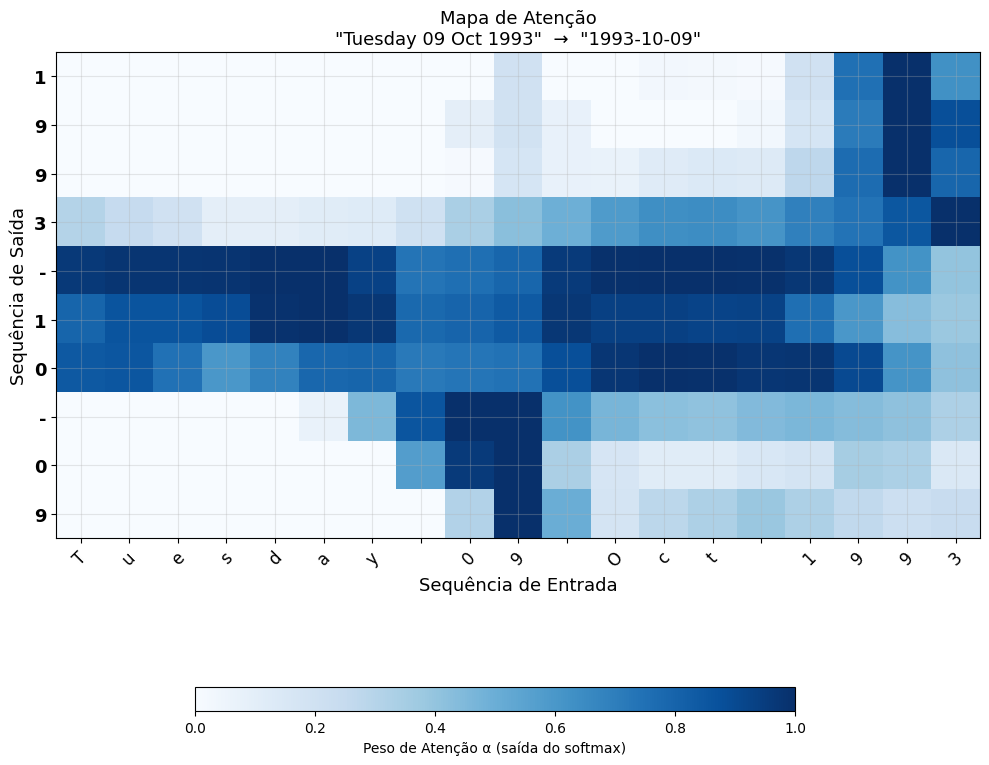

Entrada: "Tuesday 09 Oct 1993"  |  Saída predita: "1993-10-09"


<Figure size 640x480 with 0 Axes>

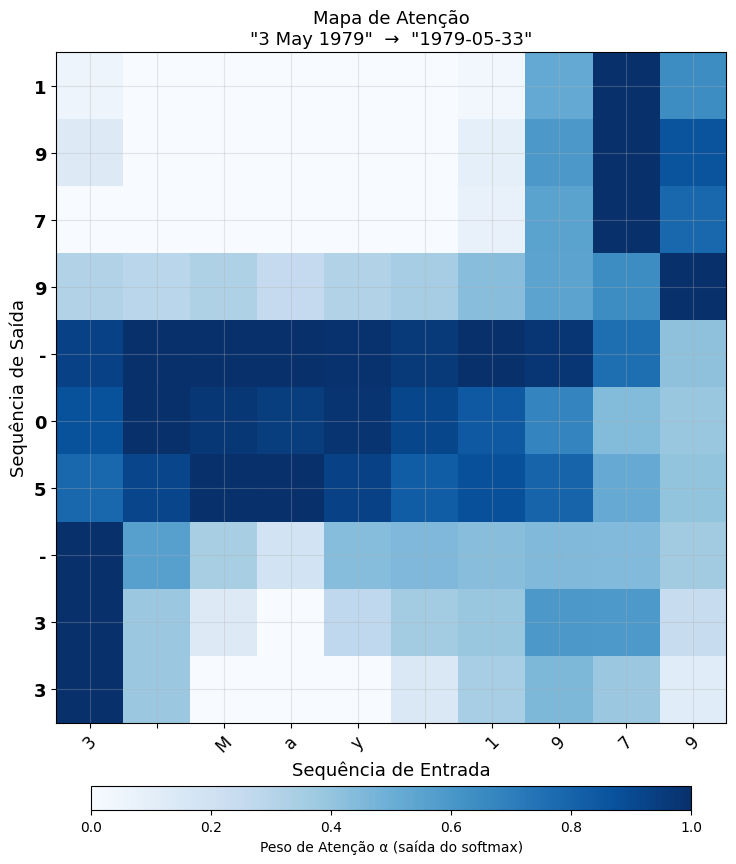

Entrada: "3 May 1979"  |  Saída predita: "1979-05-33"


<Figure size 640x480 with 0 Axes>

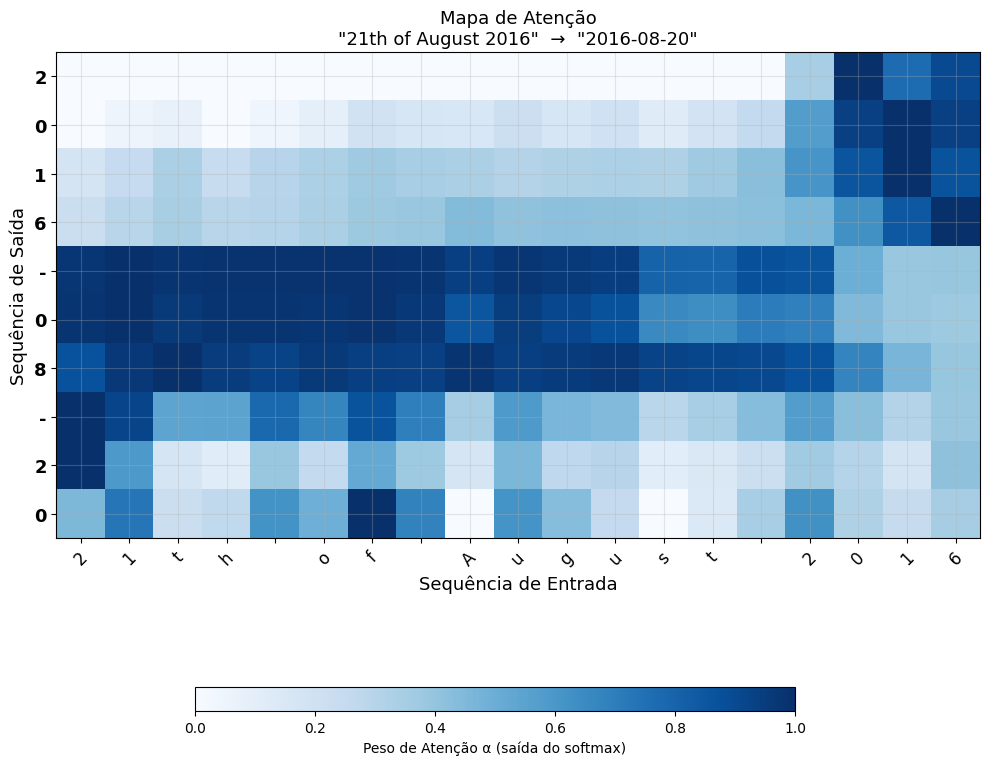

Entrada: "21th of August 2016"  |  Saída predita: "2016-08-20"


<Figure size 640x480 with 0 Axes>

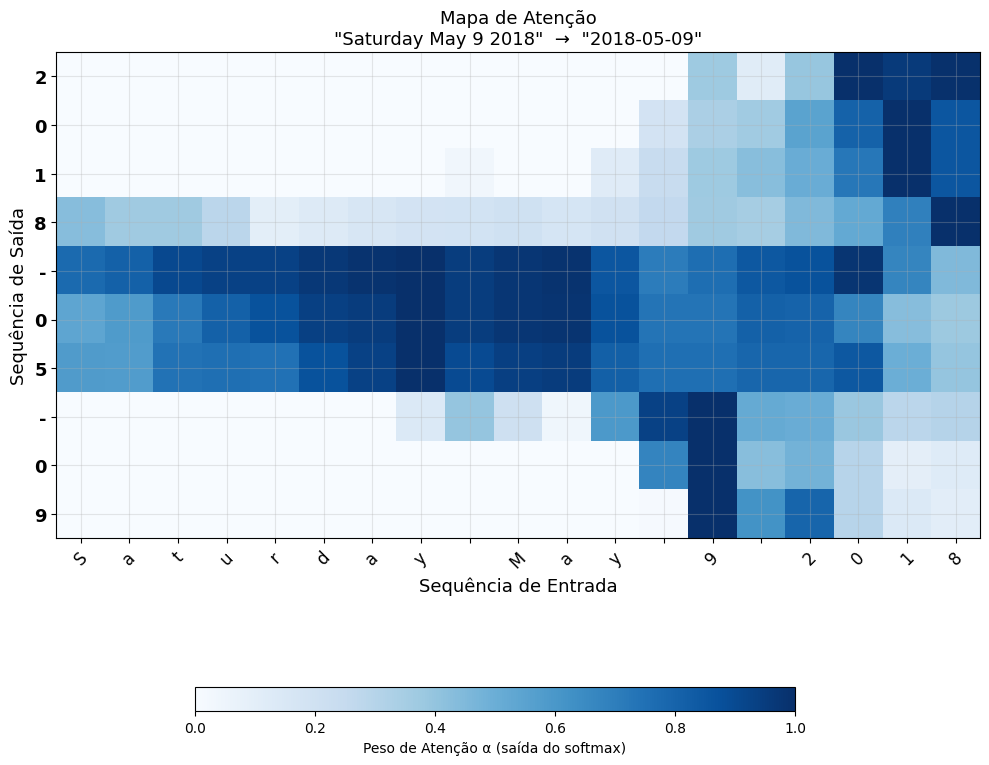

Entrada: "Saturday May 9 2018"  |  Saída predita: "2018-05-09"


<Figure size 640x480 with 0 Axes>

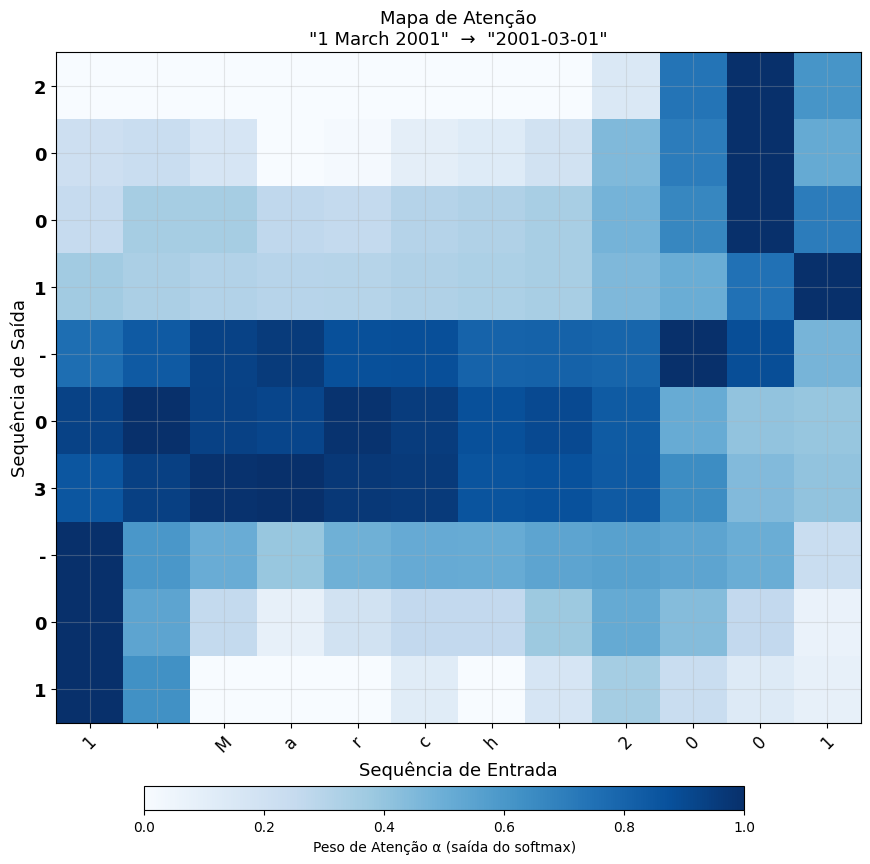

Entrada: "1 March 2001"  |  Saída predita: "2001-03-01"


In [ ]:
# ── Garante que o modelo pré-treinado está carregado ─────────────────────────
model.load_weights('model.h5')

attention_examples = [
    ('Tuesday 09 Oct 1993', 'attn_tuesday.png'),
    ('3 May 1979',          'attn_may.png'),
    ('21th of August 2016', 'attn_august.png'),
    ('Saturday May 9 2018', 'attn_saturday.png'),
    ('1 March 2001',        'attn_march.png'),
]

for sentence, fname in attention_examples:
    am = plot_attention_map(model, human_vocab, inv_machine_vocab,
                            sentence, n_s=n_s, Tx=Tx, Ty=Ty, save_as=fname)
